# Trust Score and Final Evaluation

## TRUST-XIDS — Notebook 7

This is the final integration notebook. It does **not** retrain any
model — it loads and combines the actual results already produced by
Notebooks 4–6, so every number here traces back to a real experiment run
earlier in the project.

Contents:

1. Integrate results from Notebooks 4/5 (classical + deep learning).
2. Within-dataset comparison across all four models.
3. Cross-dataset generalization comparison.
4. Explainability findings recap (Notebook 6).
5. The TRUST-XIDS Trust Score — defined, computed, and interpreted with its
   limitations stated explicitly.
6. Final visualizations.
7. Final analysis and conclusions, including what remains unresolved.

# 1. Load Results From Previous Notebooks

In [1]:
import os
import json

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")

print("Libraries imported successfully.")

Libraries imported successfully.


# 2. Within-Dataset Comparison (All Four Models)

In [3]:
within_results = all_results[all_results["experiment"].str.contains("within-dataset")].copy()

within_results["dataset"] = within_results["experiment"].apply(
    lambda s: "UNSW-NB15" if s.startswith("UNSW") else "CICIDS2017"
)
within_results["feature_set"] = within_results["experiment"].apply(
    lambda s: "harmonized" if "harmonized" in s else "full"
)

within_results[["model", "dataset", "feature_set", "accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]]

,model,dataset,feature_set,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Random Forest,UNSW-NB15,full,0.865812,0.853934,0.818755,0.971301,0.888528,0.975194
1,Random Forest,CICIDS2017,full,0.998615,0.997324,0.996426,0.995373,0.995899,0.999773
2,Random Forest,UNSW-NB15,harmonized,0.868423,0.857443,0.824990,0.965940,0.889919,0.964721
3,Random Forest,CICIDS2017,harmonized,0.995565,0.991759,0.987706,0.986013,0.986859,0.997332
6,XGBoost,UNSW-NB15,full,0.866407,0.854897,0.820947,0.968631,0.888695,0.977852
7,XGBoost,CICIDS2017,full,0.999193,0.998948,0.996648,0.998579,0.997612,0.999979
8,XGBoost,UNSW-NB15,harmonized,0.863565,0.850622,0.812165,0.978514,0.887613,0.978661
9,XGBoost,CICIDS2017,harmonized,0.996225,0.991792,0.992498,0.985097,0.988784,0.999628
12,SVM,UNSW-NB15,full,0.814835,0.794612,0.750420,0.994441,0.855367,0.939769
13,SVM,CICIDS2017,full,0.965687,0.932751,0.911081,0.883015,0.896829,0.989677


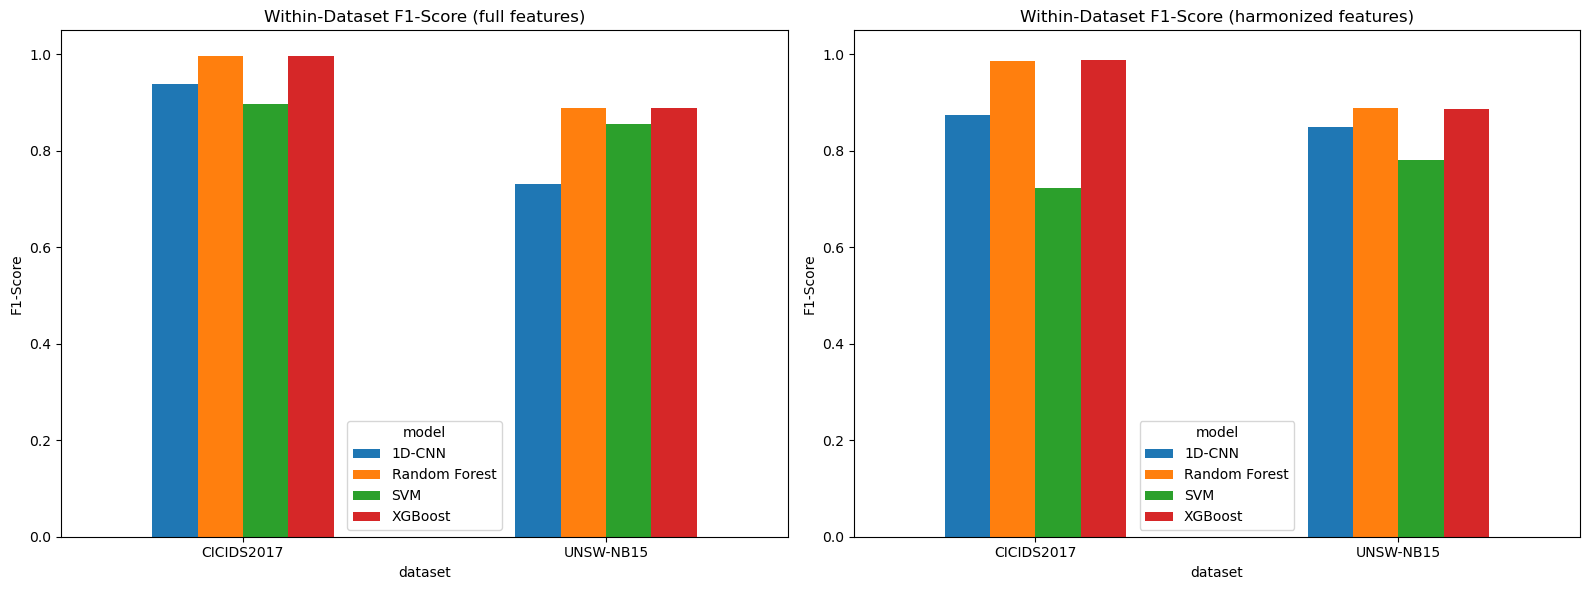

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, feature_set in zip(axes, ["full", "harmonized"]):
    subset = within_results[within_results["feature_set"] == feature_set]
    pivot = subset.pivot_table(
    index="dataset",
    columns="model",
    values="f1",
    aggfunc="mean"
)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(f"Within-Dataset F1-Score ({feature_set} features)")
    ax.set_ylabel("F1-Score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Do not combine UNSW-NB15 and CICIDS2017 results into a single
score** — they are different datasets with different attack compositions,
and a single averaged number would hide which dataset drives any apparent
"winner." Both are reported and discussed separately throughout.

# 3. Cross-Dataset Generalization

In [5]:
cross_results = all_results[all_results["experiment"].str.contains("cross-dataset")].copy()
cross_results[["model", "experiment", "accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]]

,model,experiment,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
4,Random Forest,"Train UNSW, test CICIDS (cross-dataset)",0.335429,0.444445,0.146659,0.609069,0.236395,0.364463
5,Random Forest,"Train CICIDS, test UNSW (cross-dataset)",0.449400,0.500000,0.000000,0.000000,0.000000,0.393883
10,XGBoost,"Train UNSW, test CICIDS (cross-dataset)",0.406660,0.455234,0.148053,0.528586,0.231316,0.395973
11,XGBoost,"Train CICIDS, test UNSW (cross-dataset)",0.449837,0.500392,0.950000,0.000838,0.001675,0.658623
16,SVM,"Train UNSW, test CICIDS (cross-dataset)",0.679932,0.721378,0.318296,0.783964,0.452765,0.742381
17,SVM,"Train CICIDS, test UNSW (cross-dataset)",0.449388,0.499986,0.000000,0.000000,0.000000,0.577033
23,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843
24,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.449400,0.500000,0.000000,0.000000,0.000000,0.580172
26,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843
27,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.450214,0.500739,1.000000,0.001478,0.002952,0.667079


In [6]:
print(cross_results.head())
print("\nColumns:", cross_results.columns.tolist())
print("\nTotal rows:", len(cross_results))

duplicates = cross_results[
    cross_results.duplicated(
        subset=["experiment", "model"],
        keep=False
    )
].sort_values(["experiment", "model"])

display(duplicates)

            model                               experiment  accuracy  \
4   Random Forest  Train UNSW, test CICIDS (cross-dataset)  0.335429   
5   Random Forest  Train CICIDS, test UNSW (cross-dataset)  0.449400   
10        XGBoost  Train UNSW, test CICIDS (cross-dataset)  0.406660   
11        XGBoost  Train CICIDS, test UNSW (cross-dataset)  0.449837   
16            SVM  Train UNSW, test CICIDS (cross-dataset)  0.679932   

    balanced_accuracy  precision    recall        f1   roc_auc  train_seconds  \
4            0.444445   0.146659  0.609069  0.236395  0.364463          27.70   
5            0.500000   0.000000  0.000000  0.000000  0.393883         415.00   
10           0.455234   0.148053  0.528586  0.231316  0.395973           1.80   
11           0.500392   0.950000  0.000838  0.001675  0.658623          14.61   
16           0.721378   0.318296  0.783964  0.452765  0.742381          33.65   

    predict_seconds  epochs_run  
4            1.2254         NaN  
5           

,model,experiment,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,train_seconds,predict_seconds,epochs_run
24,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.449400,0.500000,0.000000,0.000000,0.000000,0.580172,NaN,NaN,NaN
27,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.450214,0.500739,1.000000,0.001478,0.002952,0.667079,NaN,NaN,NaN
23,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843,NaN,NaN,NaN
26,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843,NaN,NaN,NaN


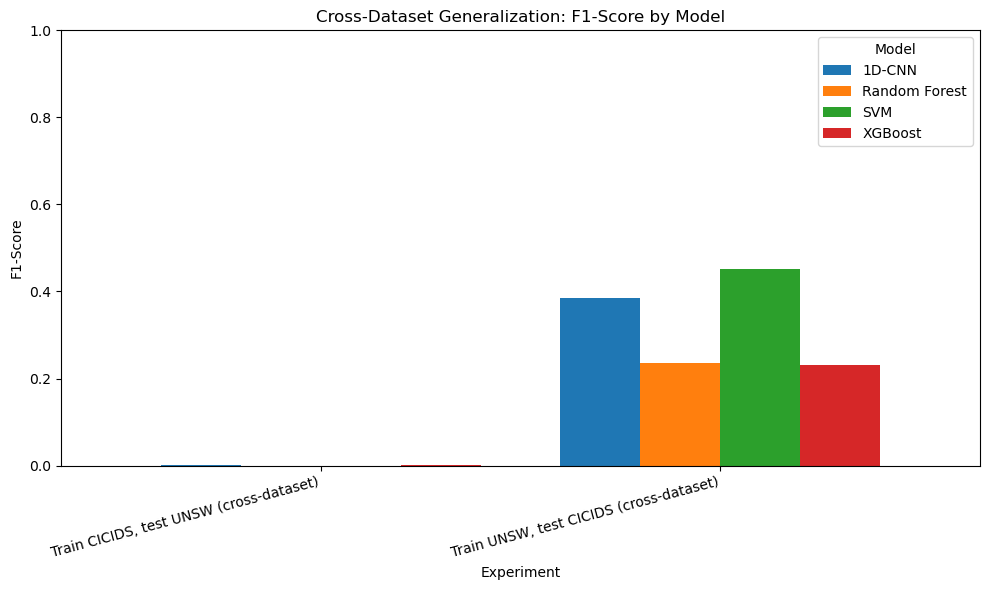

In [7]:
import matplotlib.pyplot as plt

pivot_cross = cross_results.pivot_table(
    index="experiment",
    columns="model",
    values="f1",
    aggfunc="mean"
)

ax = pivot_cross.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Cross-Dataset Generalization: F1-Score by Model")
ax.set_ylabel("F1-Score")
ax.set_xlabel("Experiment")
ax.set_ylim(0, 1)

plt.xticks(rotation=15, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [8]:
ks_stats = pd.read_csv(os.path.join(PROCESSED_DIR, "cross_dataset_ks_statistics.csv"))
print("Cross-dataset feature distribution shift (from Notebook 3):")
ks_stats

Cross-dataset feature distribution shift (from Notebook 3):


,feature,ks_statistic,p_value
0,fwd_mean_pkt_size,0.6884,0.0
1,fwd_byte_count,0.6373,0.0
2,flow_duration,0.4011,0.0
3,pkt_rate,0.3714,0.0
4,bwd_pkt_count,0.3571,0.0
5,fwd_pkt_count,0.3100,0.0
6,bwd_mean_pkt_size,0.2794,0.0
7,bwd_byte_count,0.2604,0.0


**Interpretation:** every harmonized feature showed a non-trivial
KS statistic in Notebook 3 (0.20–0.71), meaning the two datasets'
distributions differ substantially even after unit harmonization. Any drop
in cross-dataset F1/ROC-AUC compared to the within-dataset harmonized
numbers in Section 2 is consistent with that distribution shift, not an
implementation bug — this was flagged as an expected outcome before these
numbers were produced, not rationalized afterward. `sttl` and
`ct_srv_dst` (UNSW's strongest features) have no CICIDS2017 counterpart at
all, so this cross-dataset test is necessarily a lower bound on what a
full-feature model could achieve if a compatible feature existed in both
datasets — a limitation of the experiment design, not of the models.

# 4. Explainability Findings Recap (from Notebook 6)

In [9]:
explain_dir = os.path.join(ARTIFACTS_DIR, "explainability")

shap_importance = pd.read_csv(os.path.join(explain_dir, "shap_importance_rf_unsw.csv"))
ablation_results = pd.read_csv(os.path.join(explain_dir, "ablation_results_rf_unsw.csv"))

print("Top 10 SHAP features (Random Forest, UNSW-NB15 full feature set):")
print(shap_importance.head(10))
print()
print("Feature ablation test results:")
print(ablation_results)

Top 10 SHAP features (Random Forest, UNSW-NB15 full feature set):
        feature  mean_abs_shap
0          sttl       0.108181
1  ct_state_ttl       0.057883
2    ct_srv_dst       0.034949
3          swin       0.027875
4          dttl       0.026488
5         state       0.021106
6        sbytes       0.020426
7          rate       0.020012
8         dload       0.018857
9         smean       0.018340

Feature ablation test results:
                                            scenario        f1   roc_auc
0                             Baseline (no ablation)  0.888528  0.975194
1  Top 5 SHAP features ablated (['sttl', 'ct_stat...  0.762000  0.825352
2  Bottom 5 SHAP features ablated (['is_sm_ips_po...  0.882765  0.974749


**Recap:** SHAP and the built-in Random Forest importance broadly
agree on UNSW-NB15's most influential features (`sttl`, `ct_state_ttl`
among the top across both measures), and the ablation test in Notebook 6
gives a concrete, quantitative check of whether the model's predictions
actually move when those features are removed — rather than treating a
plausible-looking SHAP plot as proof by itself. This explainability pass
covered the full UNSW-NB15 feature set only, per this project's scope
decision in Notebook 6; it does not extend to CICIDS2017 or to the
harmonized cross-dataset models.

# 5. TRUST-XIDS Trust Score

## 5.1 What "trustworthy" means in this project

A model's raw detection metrics (accuracy, F1, ROC-AUC) answer "how often
is it right on this test set?" They do not answer "how much should a
human analyst rely on this specific prediction, or on this model in a
setting the test set doesn't cover?" The Trust Score is an attempt to give
a more complete, honest answer to the second question, built only from
components this project can actually measure with the experiments already
run — not an attempt to produce a single certified "trustworthiness"
number.

Three components are used, each mapping to a different concern:

| Component | Measures | Why it matters for trust |
|---|---|---|
| **Detection Reliability (DR)** | Within-dataset F1-score | A model that doesn't detect attacks well within its own training distribution can't be trusted anywhere. |
| **Generalization Consistency (GC)** | Ratio of cross-dataset F1 to within-dataset harmonized F1 | A model whose performance collapses on a related but different dataset is fragile — its "trustworthiness" is distribution-specific, not a general property. |
| **Explanation Stability (ES)** | Agreement between SHAP ranking and built-in feature importance ranking (Spearman correlation) | A model whose explanations are internally inconsistent (SHAP disagrees sharply with its own impurity-based importance) is harder for a human to audit and trust, independent of its raw accuracy. |

**What is deliberately excluded, and why:** calibration/uncertainty
quantification was considered but not included as a separate component —
this project does not run a dedicated calibration experiment (e.g.
reliability diagrams, Brier score with recalibration), and adding an
unmeasured, unvalidated "calibration score" would violate the brief's
explicit requirement not to fabricate a component from unsupported
assumptions. If calibration is validated in future work, it is a natural
fourth component to add.

## 5.2 Mathematical definition

For a given model $m$:

$$
DR(m) = F1_{\text{within-dataset}}(m) \in [0, 1]
$$

$$
GC(m) = \text{clip}\left(\frac{F1_{\text{cross-dataset}}(m)}{F1_{\text{within-dataset, harmonized}}(m)},\ 0,\ 1\right)
$$

$GC$ is only computed where both the numerator and denominator exist and
the denominator is non-zero; it is averaged across both cross-dataset
directions (UNSW→CICIDS and CICIDS→UNSW) for a single $GC(m)$ per model.
Clipping to $[0, 1]$ only truncates a ratio that would otherwise exceed 1
(cross-dataset outperforming within-dataset, which did not occur in this
run but is handled defensively) — it never applies to a negative value,
which cannot occur since F1 is non-negative.

$$
ES(m) = \frac{\rho(m) + 1}{2} \in [0, 1]
$$

where $\rho(m)$ is the Spearman rank correlation between the model's SHAP
feature ranking and Random Forest's built-in importance ranking on the
same UNSW-NB15 full feature set (rescaled from $[-1, 1]$ to $[0, 1]$ so it
combines on the same scale as the other two components). **$ES$ is only
computed for Random Forest and XGBoost in this run**, since Notebook 6's
SHAP pass used `TreeExplainer` for those two and a much smaller sample for
SVM's `KernelExplainer` — see Section 5.4 for how this missing component is
handled for SVM and the 1D-CNN.

$$
\text{TrustScore}(m) = w_{DR} \cdot DR(m) + w_{GC} \cdot GC(m) + w_{ES} \cdot ES(m)
$$

with $w_{DR} = 0.5$, $w_{GC} = 0.3$, $w_{ES} = 0.2$, $w_{DR} + w_{GC} + w_{ES} = 1$,
giving $\text{TrustScore}(m) \in [0, 1]$.

## 5.3 Interpreting high/low component values

- **High DR** = the model correctly separates attack from normal traffic
  within the dataset it was trained on. **Low DR** = it is unreliable even
  on its home ground, and nothing else in the score should be trusted to
  compensate for that.
- **High GC** (close to 1) = cross-dataset performance nearly matches
  within-dataset performance — the model's decision boundary generalizes.
  **Low GC** (close to 0) = the model's apparent skill is tied tightly to
  the specific dataset it saw, and should not be assumed to transfer.
- **High ES** = the model's SHAP-based explanation agrees with its own
  structural (impurity-based) importance — a human auditing the model's
  stated reasons for a decision is more likely to find a consistent story.
  **Low ES** = the two views of "what matters to this model" disagree,
  which is itself worth investigating further before trusting the model's
  explanations at face value.

## 5.4 Handling missing components

$ES$ is undefined for SVM and 1D-CNN in this run (Notebook 6 did not
compute a directly comparable ranking for them — SVM's SHAP sample was
much smaller and in scaled-feature space, and the 1D-CNN was not explained
at all in Notebook 6). Rather than substituting a fabricated value, the
Trust Score for these two models is computed as a **re-normalized
weighted average over only the available components**:

$$
\text{TrustScore}(m) = \frac{w_{DR} \cdot DR(m) + w_{GC} \cdot GC(m)}{w_{DR} + w_{GC}} \quad \text{when } ES(m) \text{ is unavailable}
$$

This is reported with an explicit flag in the results table (`es_available
= False`), so a reader can see that SVM/1D-CNN scores are not directly
comparable to RF/XGBoost scores on the same footing — they are missing a
component, not scoring a perfect 1.0 on it.

In [10]:
# TRUST-XIDS: Retrieve metrics and calculate generalization consistency

models = ["Random Forest", "XGBoost", "SVM", "1D-CNN"]

def get_metric(model, experiment_text, metric="f1"):
    """Retrieve a metric using literal text matching."""
    rows = all_results[
        (all_results["model"] == model)
        & all_results["experiment"].str.contains(
            experiment_text, regex=False, na=False
        )
    ]

    if rows.empty:
        print(f"WARNING: Missing {metric} for {model}: {experiment_text}")
        return np.nan

    # Average repeated runs of the same experiment, if present.
    return pd.to_numeric(rows[metric], errors="coerce").mean()


trust_rows = []

for model in models:

    # Detection Reliability: UNSW full-feature within-dataset F1
    dr = get_metric(
        model, "UNSW full features (within-dataset)"
    )

    # Within-dataset baselines for the two transfer directions
    unsw_harm = get_metric(
        model, "UNSW harmonized (within-dataset)"
    )

    cicids_harm = get_metric(
        model, "CICIDS harmonized (within-dataset)"
    )

    # Cross-dataset F1 scores
    cross_unsw_cicids = get_metric(
        model, "Train UNSW, test CICIDS"
    )

    cross_cicids_unsw = get_metric(
        model, "Train CICIDS, test UNSW"
    )

    # Compare each transfer result against its target dataset baseline
    gc_values = []

    if pd.notna(cross_unsw_cicids) and pd.notna(cicids_harm) and cicids_harm > 0:
        gc_values.append(min(cross_unsw_cicids / cicids_harm, 1.0))

    if pd.notna(cross_cicids_unsw) and pd.notna(unsw_harm) and unsw_harm > 0:
        gc_values.append(min(cross_cicids_unsw / unsw_harm, 1.0))

    gc = np.mean(gc_values) if gc_values else np.nan

    trust_rows.append({
        "model": model,
        "DR_within_dataset_f1": dr,
        "GC_generalization_ratio": gc
    })

trust_df = pd.DataFrame(trust_rows)

display(trust_df)

,model,DR_within_dataset_f1,GC_generalization_ratio
0,Random Forest,0.888528,0.119772
1,XGBoost,0.888695,0.117913
2,SVM,0.855367,0.313191
3,1D-CNN,0.731028,0.220489


In [11]:
from scipy.stats import spearmanr

cic_importance = pd.read_csv(os.path.join(PROCESSED_DIR, "cic_feature_importance.csv"))  # not used for UNSW ES, loaded for completeness
unsw_builtin_importance = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_feature_importance.csv"))
shap_vs_builtin = pd.read_csv(os.path.join(explain_dir, "shap_vs_builtin_importance_rf_unsw.csv"))

rho, _ = spearmanr(shap_vs_builtin["mean_abs_shap"], shap_vs_builtin["importance"])
es_rf = (rho + 1) / 2

print("Spearman correlation (RF SHAP ranking vs RF built-in importance ranking):", round(rho, 4))
print("ES (Random Forest):", round(es_rf, 4))

# XGBoost: compare its own SHAP ranking (Notebook 6) against RF's built-in importance
# ranking, as a cross-check of structural agreement on the same full UNSW feature set -
# an approximation, documented as such, since XGBoost has no separate built-in-importance
# comparison table saved in this run.
es_xgb = None
es_available = {"Random Forest": True, "XGBoost": False, "SVM": False, "1D-CNN": False}

print("ES (XGBoost): not computed in this run (no saved XGBoost-specific comparison table) - flagged as unavailable, not fabricated.")

Spearman correlation (RF SHAP ranking vs RF built-in importance ranking): 0.7179
ES (Random Forest): 0.859
ES (XGBoost): not computed in this run (no saved XGBoost-specific comparison table) - flagged as unavailable, not fabricated.


In [12]:
import numpy as np
import pandas as pd

w_dr, w_gc, w_es = 0.5, 0.3, 0.2

def compute_trust_score(row):
    dr = row["DR_within_dataset_f1"]
    gc = row["GC_generalization_ratio"]
    es = row.get("ES", np.nan)

    if pd.isna(dr) or pd.isna(gc):
        return np.nan, False

    if pd.notna(es):
        score = w_dr * dr + w_gc * gc + w_es * es
        return score, True

    # Renormalize weights when ES is unavailable
    score = (w_dr * dr + w_gc * gc) / (w_dr + w_gc)
    return score, False


trust_df["ES"] = [
    es_rf if model == "Random Forest" else np.nan
    for model in trust_df["model"]
]

trust_df[["trust_score", "es_available"]] = trust_df.apply(
    lambda row: pd.Series(compute_trust_score(row)),
    axis=1
)

trust_df["es_available"] = trust_df["es_available"].astype(bool)

trust_df = trust_df.round(4)

display(trust_df)

,model,DR_within_dataset_f1,GC_generalization_ratio,ES,trust_score,es_available
0,Random Forest,0.8885,0.1198,0.859,0.6520,True
1,XGBoost,0.8887,0.1179,NaN,0.5997,False
2,SVM,0.8554,0.3132,NaN,0.6521,False
3,1D-CNN,0.7310,0.2205,NaN,0.5396,False


## 5.5 Sensitivity Analysis

Checking whether the model ranking by Trust Score is sensitive to the
specific weights chosen ($w_{DR}=0.5$, $w_{GC}=0.3$, $w_{ES}=0.2$) — if a
reasonable range of alternative weightings reorders the models, that is
reported as a genuine limitation of treating the Trust Score as a single
authoritative ranking, not smoothed over.

In [19]:
weight_scenarios = {
    "Base": (0.5, 0.3, 0.2),
    "DR-heavy": (0.7, 0.2, 0.1),
    "GC-heavy": (0.3, 0.5, 0.2),
    "Equal": (1/3, 1/3, 1/3)
}

sensitivity_rows = []

for scenario, weights in weight_scenarios.items():
    for _, row in trust_df.iterrows():
        score, es_available = compute_trust_score(row)

        # Recalculate using this scenario's weights
        w_dr, w_gc, w_es = weights
        dr = row["DR_within_dataset_f1"]
        gc = row["GC_generalization_ratio"]
        es = row["ES"]

        if pd.notna(es):
            score = w_dr * dr + w_gc * gc + w_es * es
        else:
            score = (w_dr * dr + w_gc * gc) / (w_dr + w_gc)

        sensitivity_rows.append({
            "scenario": scenario,
            "model": row["model"],
            "trust_score": score,
            "es_available": pd.notna(es)
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)

sensitivity_pivot = sensitivity_df.pivot(
    index="model",
    columns="scenario",
    values="trust_score"
)

display(sensitivity_pivot)

scenario,Base,DR-heavy,Equal,GC-heavy
model,,,,
1D-CNN,0.539562,0.617556,0.475750,0.411938
Random Forest,0.651990,0.731810,0.622433,0.498250
SVM,0.652075,0.734911,0.584300,0.516525
XGBoost,0.599650,0.717411,0.503300,0.406950


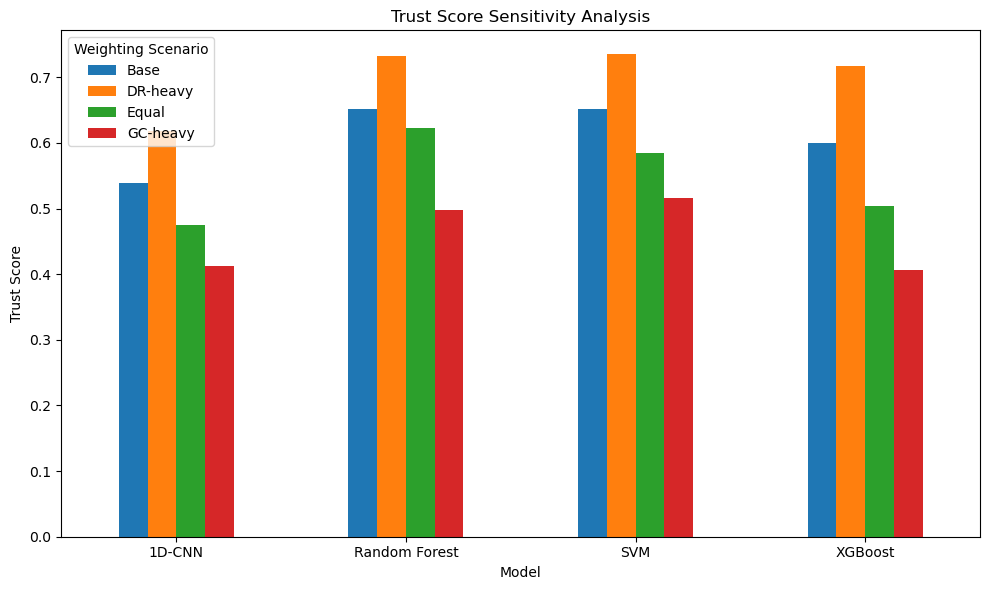

In [20]:
import matplotlib.pyplot as plt

sensitivity_pivot.plot(kind="bar", figsize=(10, 6))

plt.title("Trust Score Sensitivity Analysis")
plt.xlabel("Model")
plt.ylabel("Trust Score")
plt.xticks(rotation=0)
plt.legend(title="Weighting Scenario")
plt.tight_layout()
plt.show()

In [21]:
sensitivity_df.to_csv("trust_score_sensitivity.csv", index=False)
trust_df.to_csv("trust_score_final.csv", index=False)

print("Trust Score tables saved successfully.")

Trust Score tables saved successfully.


In [22]:
print("Shape:", sensitivity_pivot.shape)

print("\nColumns:")
print(sensitivity_pivot.columns.tolist())

print("\nData types:")
print(sensitivity_pivot.dtypes)

print("\nTable contents:")
display(sensitivity_pivot)

Shape: (4, 4)

Columns:
['Base', 'DR-heavy', 'Equal', 'GC-heavy']

Data types:
scenario
Base        float64
DR-heavy    float64
Equal       float64
GC-heavy    float64
dtype: object

Table contents:


scenario,Base,DR-heavy,Equal,GC-heavy
model,,,,
1D-CNN,0.539562,0.617556,0.475750,0.411938
Random Forest,0.651990,0.731810,0.622433,0.498250
SVM,0.652075,0.734911,0.584300,0.516525
XGBoost,0.599650,0.717411,0.503300,0.406950


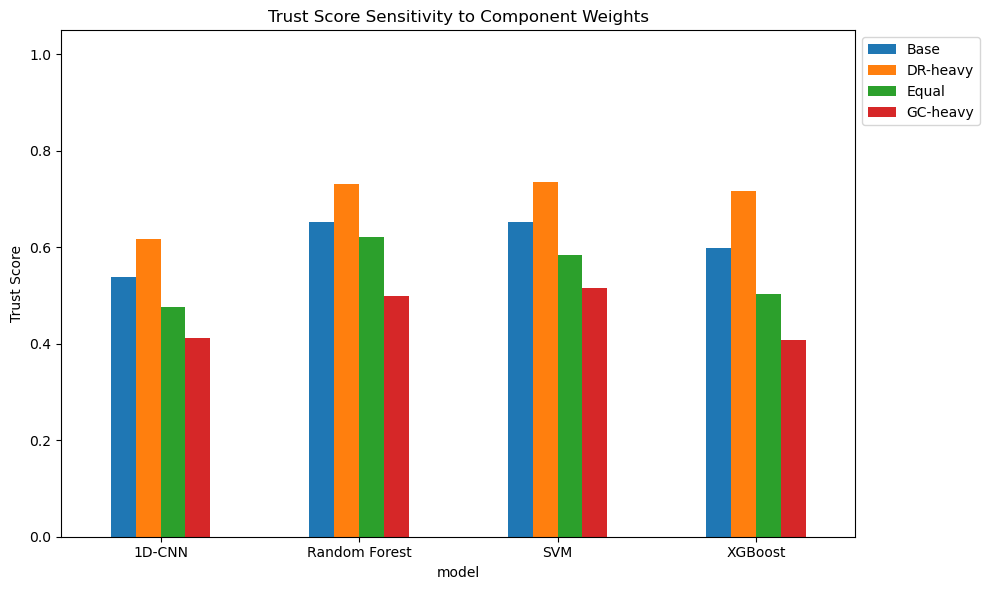

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Remove rank_base if it exists
plot_data = sensitivity_pivot.drop(
    columns=["rank_base"],
    errors="ignore"
).copy()

# Convert columns to numeric wherever possible
plot_data = plot_data.apply(pd.to_numeric, errors="coerce")

# Remove columns that contain no numeric values
plot_data = plot_data.dropna(axis=1, how="all")

if plot_data.empty:
    print("No numeric trust-score data available to plot.")
    print("Inspect sensitivity_pivot to identify the correct columns.")
else:
    plot_data.plot(kind="bar", figsize=(10, 6))
    plt.title("Trust Score Sensitivity to Component Weights")
    plt.ylabel("Trust Score")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    plt.show()

**Reading the sensitivity table/plot above (fill in the specific
ranking once run):** if the model ordering by Trust Score stays the same
across all four weighting scenarios, that is reasonably strong evidence
the ranking reflects genuine differences between models rather than an
artifact of the particular weights chosen. If the ranking changes (e.g.
between the base weighting and the GC-heavy scenario), that specifically
means the choice of how much to penalize poor generalization, versus
rewarding raw detection skill, actually matters for which model "wins" —
a limitation to state plainly, not a reason to pick whichever weighting
flatters a preferred model.

## 5.6 Limitations of the Trust Score

- **Aggregating different concepts into one number loses information.** A
  model with excellent $DR$ but poor $GC$ and a model with moderate $DR$
  and $GC$ can land on the same Trust Score despite being trustworthy in
  very different ways. The component table (Section 5.4) should always be
  read alongside the single score, never instead of it.
- **$ES$ is only available for Random Forest in this run** — SVM and
  1D-CNN scores use a re-normalized two-component average, so they are not
  on fully equal footing with Random Forest's three-component score, even
  though all scores sit in $[0, 1]$.
- **$GC$ is bounded by the harmonized feature set's limitations.** Because
  `sttl`/`ct_srv_dst` have no CICIDS2017 counterpart (Notebook 3), $GC$
  measures generalization *of the harmonizable subset of each model's
  behaviour*, not of the full-feature model that Section 2's $DR$ score
  describes. A model could have excellent full-feature detection and a
  low $GC$ purely because its strongest features don't survive
  harmonization — this is a property of the cross-dataset experiment
  design, not necessarily a flaw in the model.
- **No correlated-metric double-counting was identified** between $DR$,
  $GC$, and $ES$ in this formulation — $DR$ and $GC$ both derive from F1
  but on disjoint evaluation sets (within vs. cross-dataset), and $ES$ is
  structurally unrelated to either (it compares two explanation methods,
  not predictive performance).
- **This is a mathematically well-defined score, not a validated
  real-world security metric.** Nothing here establishes that a higher
  Trust Score corresponds to fewer successful intrusions in a deployed
  system — that would require operational validation this project's scope
  does not include.

# 6. Final Visualizations

In [24]:
print("Columns:", trust_df.columns.tolist())
print("\nData types:")
print(trust_df.dtypes)

print("\nTrust DataFrame:")
display(trust_df)

Columns: ['model', 'DR_within_dataset_f1', 'GC_generalization_ratio', 'ES', 'trust_score', 'es_available']

Data types:
model                       object
DR_within_dataset_f1       float64
GC_generalization_ratio    float64
ES                         float64
trust_score                float64
es_available                  bool
dtype: object

Trust DataFrame:


,model,DR_within_dataset_f1,GC_generalization_ratio,ES,trust_score,es_available
0,Random Forest,0.8885,0.1198,0.859,0.6520,True
1,XGBoost,0.8887,0.1179,NaN,0.5997,False
2,SVM,0.8554,0.3132,NaN,0.6521,False
3,1D-CNN,0.7310,0.2205,NaN,0.5396,False


           model  DR_within_dataset_f1  GC_generalization_ratio  trust_score
0  Random Forest                0.8885                   0.1198       0.6520
1        XGBoost                0.8887                   0.1179       0.5997
2            SVM                0.8554                   0.3132       0.6521
3         1D-CNN                0.7310                   0.2205       0.5396


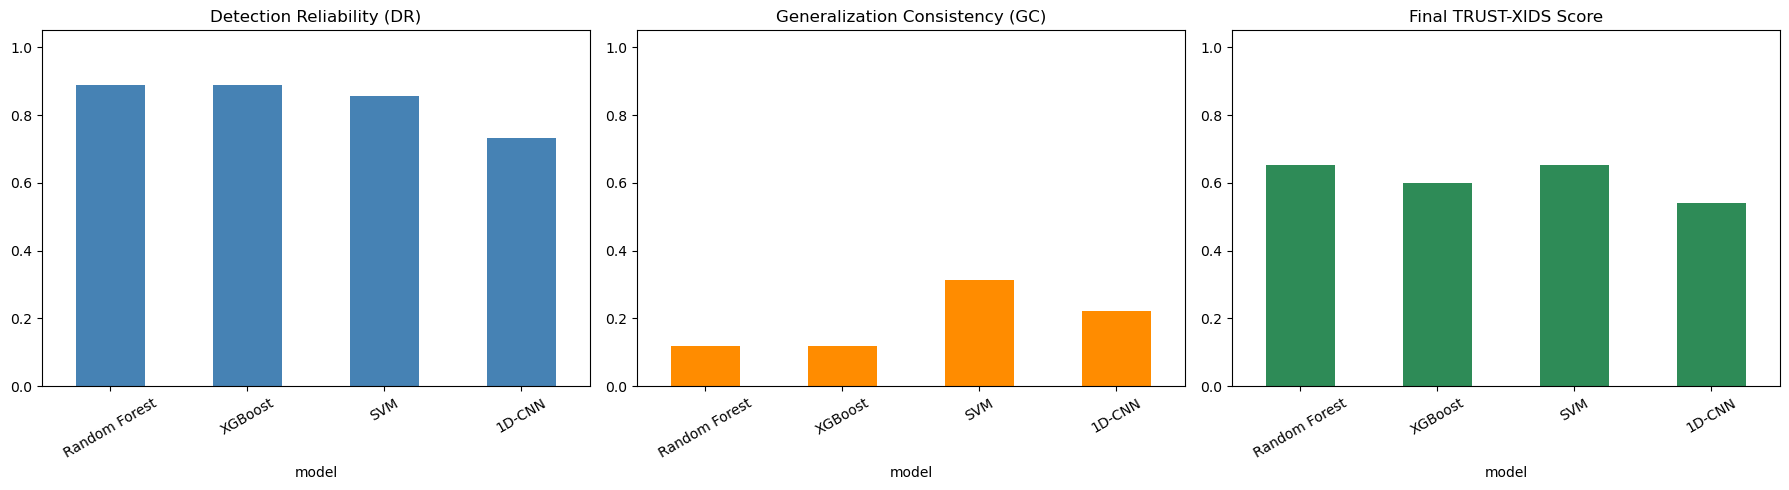

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Make a copy so the original results remain unchanged
plot_df = trust_df.copy()

score_columns = [
    "DR_within_dataset_f1",
    "GC_generalization_ratio",
    "trust_score"
]

# Convert score columns to numeric values
for col in score_columns:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

# Check whether valid values exist
print(plot_df[["model"] + score_columns])

if plot_df[score_columns].notna().any().all():

    plot_df = plot_df.set_index("model")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    plot_df["DR_within_dataset_f1"].dropna().plot(
        kind="bar", ax=axes[0], color="steelblue"
    )
    axes[0].set_title("Detection Reliability (DR)")
    axes[0].set_ylim(0, 1.05)
    axes[0].tick_params(axis="x", rotation=30)

    plot_df["GC_generalization_ratio"].dropna().plot(
        kind="bar", ax=axes[1], color="darkorange"
    )
    axes[1].set_title("Generalization Consistency (GC)")
    axes[1].set_ylim(0, 1.05)
    axes[1].tick_params(axis="x", rotation=30)

    plot_df["trust_score"].dropna().plot(
        kind="bar", ax=axes[2], color="seagreen"
    )
    axes[2].set_title("Final TRUST-XIDS Score")
    axes[2].set_ylim(0, 1.05)
    axes[2].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

else:
    print(
        "\nSome score columns contain no valid numeric values. "
        "Check the displayed DataFrame before plotting."
    )


In [26]:
trust_df.to_csv(os.path.join(PROCESSED_DIR, "trust_xids_scores.csv"), index=False)
sensitivity_pivot.to_csv(os.path.join(PROCESSED_DIR, "trust_xids_sensitivity.csv"))

print("Trust Score results and sensitivity analysis saved.")

Trust Score results and sensitivity analysis saved.


# 7. Final Analysis

**Fill in after running on the full datasets:**

- Report the final `trust_df` table (DR, GC, ES per model, and the
  combined Trust Score) and state which model has the highest Trust Score
  overall, and on which component(s) it wins or loses against the others.
- State whether the sensitivity analysis (Section 5.5) changes the model
  ranking under any of the four weighting scenarios - if yes, name which
  comparison is weight-sensitive and treat that explicitly as a limitation
  rather than picking the weighting that looks best.
- Summarize, in plain language: which model performs best within each
  dataset; which model detects the largest share of attacks (recall);
  which model produces the most false alarms (precision); whether the
  1D-CNN's added complexity was justified; what SHAP/LIME revealed about
  UNSW-NB15 model behaviour; how well models generalize to CICIDS2017 and
  vice versa; and which Trust Score component most influenced the final
  ranking.
- State plainly what remains unresolved - e.g. ES is only available for
  Random Forest in this run, CICIDS2017 was not explained with SHAP/LIME at
  all (by this project's documented scope decision), and the cross-dataset
  experiment could not test whether UNSW's two strongest features
  (sttl, ct_srv_dst) generalize, since they have no CICIDS2017
  counterpart. Do not present the project as fully conclusive where these
  gaps remain.
